## Data reading

In [40]:
import polars as pl

DATA_DIR = "data"

dfs: list[pl.LazyFrame] = []
for month in range(1, 13):
    df = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet")
    df = df.with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
    dfs.append(df)

df_rides = pl.concat(dfs)

In [41]:
df_taxi_zones = pl.scan_csv(f"{DATA_DIR}/taxi_zone_lookup.csv")

In [42]:
df_rides = df_rides.filter(
    pl.col("tpep_pickup_datetime").dt.date().is_between(
        pl.date(2024, 1, 1),
        pl.date(2025, 1, 1)
    ),
    pl.col("tpep_dropoff_datetime").dt.date().is_between(
        pl.date(2024, 1, 1),
        pl.date(2025, 1, 1)
    ),
)

In [43]:
df_rides.schema, df_taxi_zones.schema

/var/folders/90/55wz2vrd4375m33q50580xhc0000gn/T/ipykernel_32000/2019457491.py:1: PerformanceWarning: Resolving the schema of a LazyFrame is a potentially expensive operation. Use `LazyFrame.collect_schema()` to get the schema without this warning.
  df_rides.schema, df_taxi_zones.schema


(Schema([('VendorID', Int32),
         ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)),
         ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)),
         ('passenger_count', Int64),
         ('trip_distance', Float64),
         ('RatecodeID', Int64),
         ('store_and_fwd_flag', String),
         ('PULocationID', Int32),
         ('DOLocationID', Int32),
         ('payment_type', Int64),
         ('fare_amount', Float64),
         ('extra', Float64),
         ('mta_tax', Float64),
         ('tip_amount', Float64),
         ('tolls_amount', Float64),
         ('improvement_surcharge', Float64),
         ('total_amount', Float64),
         ('congestion_surcharge', Float64),
         ('Airport_fee', Float64)]),
 Schema([('LocationID', Int64),
         ('Borough', String),
         ('Zone', String),
         ('service_zone', String)]))

In [44]:
df_rides.select(
    pl.col("VendorID").min().alias("max_vendor_id"),
    pl.col("VendorID").max().alias("min_vendor_id"),
    pl.col("RatecodeID").min().alias("min_ratecode_id"),
    pl.col("RatecodeID").max().alias("max_ratecode_id"),
).collect()

max_vendor_id,min_vendor_id,min_ratecode_id,max_ratecode_id
i32,i32,i64,i64
1,7,1,99


In [45]:
df_rides = df_rides.with_columns(
    pl.col("passenger_count").cast(pl.UInt8),
    pl.col("PULocationID").cast(pl.UInt16),
    pl.col("DOLocationID").cast(pl.UInt16),
    pl.col("VendorID").cast(pl.UInt8),
    pl.col("payment_type").cast(pl.UInt8),
    pl.col("RatecodeID").cast(pl.UInt8)
)

In [46]:
df_rides.select(
    pl.col("store_and_fwd_flag")
).unique().collect()

store_and_fwd_flag
str
null
"""N"""
"""Y"""


In [47]:
df_rides = df_rides.with_columns(
    (pl.col("store_and_fwd_flag") == "Y")
    .alias("store_and_fwd_flag")
)

In [48]:
df_rides.select(
    pl.col("store_and_fwd_flag")
).unique().collect()

store_and_fwd_flag
bool
null
false
true


## Data cleaning and filtering

In [49]:
# 1. fill NULL values in passengers_count with 1
# 2. remove rides with zero passengers
# 3. if a ride has over 6 passengers, replace the value with 6
# 4. remove rides lasting over 2 hours
# 5. in all money-related columns, replace values with absolute value to fix negative amounts
# 6. remove rides with over 1000 dollars in any money-related column
# 7. remove rows with values of RatecodeID or VendorID missing or outside those defined in the data dictionary

MONEY_RELATED_COLUMNS = [
    "fare_amount", 
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee"
]

df_rides = df_rides.with_columns(
    pl.col("passenger_count")
    .fill_null(1)
).filter(
    pl.col("passenger_count").gt(0)
).with_columns(
    pl.col("passenger_count")
    .clip(upper_bound=6)
).filter(
    (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime"))
    .dt.total_hours()
    .le(2)
).with_columns(
    pl.col(MONEY_RELATED_COLUMNS).abs()
).filter(
    pl.all_horizontal(
        pl.col(MONEY_RELATED_COLUMNS).lt(1000)
    )
).filter(
    pl.col("RatecodeID").is_not_null(),
    pl.col("VendorID").is_not_null(),
    pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6, 99]),
    pl.col("VendorID").is_in([1, 2, 6, 7])
)

In [50]:
df_rides = df_rides.collect().lazy()

## Data transformation

In [ ]:
# 1. combine payment type values for "No charge", "Dispute", "Unknown" and "Voided trip" into one type,
# so we have only credit card, cash, or other

df_rides = df_rides.with_columns(
    pl.col("payment_type").replace(
        old=[3, 4, 5, 6],
        new=3
    )
)

In [ ]:
# 2. replace PULocationID and DOLocationID with borough names by joining taxi zone lookup and removing unnecessary columns

df_rides = df_rides.join(
    df_taxi_zones.select(
        pl.col("LocationID"),
        pl.col("Borough").alias("PUBorough")
    ),
    left_on=pl.col("PULocationID"),
    right_on=pl.col("LocationID"),
    how="left"
).join(
    df_taxi_zones.select(
        pl.col("LocationID"),
        pl.col("Borough").alias("DOBorough")
    ),
    left_on=pl.col("DOLocationID"),
    right_on=pl.col("LocationID"),
    how="left"
).drop(
    "PULocationID",
    "DOLocationID"
)

In [66]:
# 3. add boolean variable is_airport_ride, true if there is non-zero airport fee

df_rides = df_rides.with_columns(
    is_airport_ride=pl.col("Airport_fee").gt(0)
)

In [67]:
# 4. add boolean variable is_rush_hour, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays

df_rides = df_rides.with_columns(
    is_rush_hour=(
        pl.col("tpep_pickup_datetime").dt.weekday().le(5).and_(
            pl.col("tpep_pickup_datetime").dt.time().is_between(
                pl.time(6, 30),
                pl.time(9, 30)
            ).or_(
                pl.col("tpep_pickup_datetime").dt.time().is_between(
                    pl.time(15, 30),
                    pl.time(20, 0)
                )
            )
        )
    )
)

## Feature extraction

In [76]:
# apply dummy encoding to features
import polars.selectors as cs

df_rides = (
    df_rides
    .collect()
    .to_dummies(
        columns=["payment_type", "PUBorough", "DOBorough"]
    )
    .with_columns(
        cs.starts_with("payment_type_", "PUBorough_", "DOBorough_").cast(pl.Boolean)
    )
    .lazy()
)

In [100]:
df_daily = (
    df_rides
    .with_columns(
        pl.col("tpep_pickup_datetime").dt.date().alias("date")
    )
    .group_by("date")
    .agg(
        total_rides=pl.len(),
        airport_rides=pl.col("is_airport_ride").sum(),
        rush_hour_rides=pl.col("is_rush_hour").sum(),
        avg_fare_amount=pl.col("fare_amount").mean(),
        median_distance=pl.col("trip_distance").median(),
        sum_total_amount=pl.col("total_amount").sum(),
        total_congestion_surcharge=pl.col("congestion_surcharge").sum(),
        total_passengers=pl.col("passenger_count").sum(),
    amount_paid_by_card=(
        pl.col("total_amount")
        .filter(pl.col("payment_type_1"))
        .sum()
    ),
    amount_paid_by_cash=(
        pl.col("total_amount")
        .filter(pl.col("payment_type_2"))
        .sum()
    ),
    amount_paid_by_other=(
        pl.col("total_amount")
        .filter(pl.col("payment_type_3"))
        .sum()
    ),
    )
    .with_columns(
        quarter=pl.col("date").dt.quarter(),
        month=pl.col("date").dt.month(),
        day_of_month=pl.col("date").dt.day(),
        day_of_week=pl.col("date").dt.weekday(),
        is_weekend=pl.col("date").dt.weekday().ge(6)
    )
    .sort(pl.col("date"))
)

In [101]:
# I used collect() + write_parquet() because sink_parquet() resulted in InvalidOperationError (probably some version mismatch)

df_daily = df_daily.collect()
df_daily.write_parquet(f"{DATA_DIR}/dataset.parquet")

## Data analysis

In [102]:
# 1. print shape

df_daily.shape

(366, 17)

In [103]:
# 2. show top rows

df_daily.head()

date,total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_distance,sum_total_amount,total_congestion_surcharge,total_passengers,amount_paid_by_card,amount_paid_by_cash,amount_paid_by_other,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,i64,f64,f64,f64,i8,i8,i8,i8,bool
2024-01-01,69670,8353,19398,22.219974,2.09,2.1853e6,156130.75,109145,1.7447e6,384743.61,55778.86,1,1,1,1,false
2024-01-02,72600,9829,31022,21.523636,1.82,2.2522e6,160632.5,104093,1.8030e6,397770.09,51441.03,1,1,2,2,false
2024-01-03,79614,9169,33406,20.208392,1.75,2.3368e6,178067.5,111051,1.8697e6,417507.01,49561.25,1,1,3,3,false
2024-01-04,99101,8273,43583,18.879264,1.75,2.7624e6,226650.0,135847,2.2574e6,445136.95,59823.2,1,1,4,4,false
2024-01-05,98872,7463,40525,18.258754,1.7,2.6782e6,227550.0,137181,2.1994e6,420978.26,57798.23,1,1,5,5,false


In [104]:
# 3. describe statistics

df_daily.describe()

statistic,date,total_rides,airport_rides,rush_hour_rides,avg_fare_amount,median_distance,sum_total_amount,total_congestion_surcharge,total_passengers,amount_paid_by_card,amount_paid_by_cash,amount_paid_by_other,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",100141.915301,8990.199454,29962.032787,19.980507,1.719331,2.9155e6,230239.359344,135016.945355,2.4637e6,373328.374754,78429.164945,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15389.315534,1720.291197,19708.923704,1.210568,0.10057,463485.679415,37878.95429,18739.908913,430470.311473,36500.436851,17405.019591,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",47394.0,3356.0,0.0,16.691075,1.5,1.3262e6,107827.5,74202.0,996620.34,240729.07,41303.84,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",89621.0,7871.0,0.0,19.139729,1.66,2.5851e6,203506.0,122264.0,2.1718e6,352859.1,65782.48,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",100793.0,9033.0,39526.0,20.001156,1.7,2.9217e6,232892.5,134113.0,2.4668e6,376665.61,79736.24,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",110862.0,10147.0,44804.0,20.731037,1.77,3.2249e6,256977.0,147295.0,2.7469e6,400186.16,90710.19,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",141966.0,14929.0,56725.0,24.476789,2.2,4.4927e6,330525.0,199496.0,3.9404e6,451228.63,123977.41,4.0,12.0,31.0,7.0,1.0


In [105]:
# 4. print schema

df_daily.schema 

Schema([('date', Date),
        ('total_rides', UInt32),
        ('airport_rides', UInt32),
        ('rush_hour_rides', UInt32),
        ('avg_fare_amount', Float64),
        ('median_distance', Float64),
        ('sum_total_amount', Float64),
        ('total_congestion_surcharge', Float64),
        ('total_passengers', Int64),
        ('amount_paid_by_card', Float64),
        ('amount_paid_by_cash', Float64),
        ('amount_paid_by_other', Float64),
        ('quarter', Int8),
        ('month', Int8),
        ('day_of_month', Int8),
        ('day_of_week', Int8),
        ('is_weekend', Boolean)])

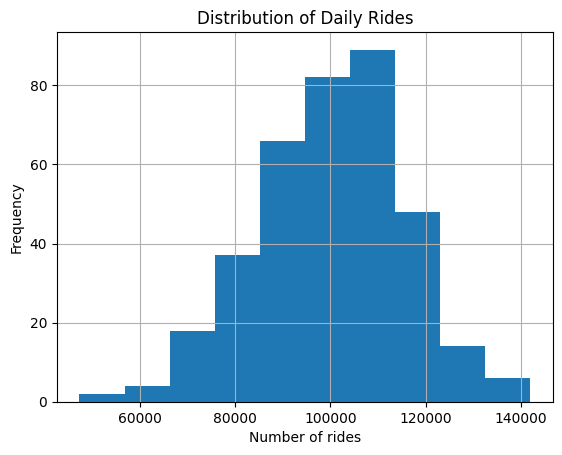

In [106]:
# 5. plot target variable (daily number of rides):

import matplotlib.pyplot as plt

df_daily.select(
    pl.col("total_rides")
).to_pandas().hist()


plt.title("Distribution of Daily Rides")
plt.xlabel("Number of rides")
plt.ylabel("Frequency")
plt.show()

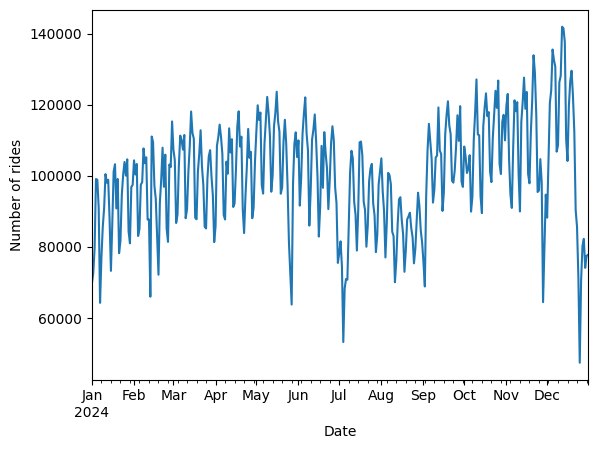

In [109]:
df_daily.select(
    pl.col("total_rides"),
    pl.col("date")
).to_pandas().plot.line(
    x="date",
    y="total_rides",
    legend=False
)

plt.xlabel("Date")
plt.ylabel("Number of rides")
plt.show()